# Practical 6: Hybrid Recommender System

## Aim
Implement and evaluate item-based collaborative filtering, content-based recommendation, and a weighted hybrid on MovieLens Small.

\[
s_H(u,i)=\alpha s'_{CF}(u,i)+(1-\alpha)s'_{CB}(u,i)
\]

All three models use the same chronological holdout and are evaluated with HR@10, MRR@10, and NDCG@10.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer

Mounted at /content/drive


## 1. LOAD DATA


In [ ]:
DATA_FOLDER = '/content/drive/MyDrive/RS/ML_Small'

RATINGS_FILE = os.path.join(DATA_FOLDER, 'ratings.csv')
MOVIES_FILE = os.path.join(DATA_FOLDER, 'movies.csv')
TAGS_FILE = os.path.join(DATA_FOLDER, 'tags.csv')

TOP_N = 10
RANKING_K = 10
RELEVANCE_THRESHOLD = 4.0
ALPHA = 0.60
DEMO_USER_ID = 25
MAX_EVAL_USERS = None
EVAL_RANDOM_STATE = 42

In [ ]:
# 1. LOAD DATA
# ------------------------------------------------------------

ratings = pd.read_csv(RATINGS_FILE)
movies = pd.read_csv(MOVIES_FILE)

if os.path.exists(TAGS_FILE):
    tags = pd.read_csv(TAGS_FILE)
    USE_TAGS = True
else:
    tags = pd.DataFrame()
    USE_TAGS = False

print('=' * 70)
print('MOVIELENS SMALL')
print('=' * 70)
print('Ratings shape:', ratings.shape)
print('Movies shape :', movies.shape)
print('Tags loaded  :', USE_TAGS)

display(ratings.head())
display(movies.head())
if USE_TAGS:
    display(tags.head())

# ------------------------------------------------------------


MOVIELENS SMALL
Ratings shape: (100836, 4)
Movies shape : (9742, 3)
Tags loaded  : True


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


## 2. CHECK REQUIRED COLUMNS


In [ ]:
# 2. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_rating_columns = {'userId', 'movieId', 'rating', 'timestamp'}
required_movie_columns = {'movieId', 'title', 'genres'}

if not required_rating_columns.issubset(ratings.columns):
    raise ValueError('ratings.csv must contain userId, movieId, rating and timestamp.')

if not required_movie_columns.issubset(movies.columns):
    raise ValueError('movies.csv must contain movieId, title and genres.')

# ------------------------------------------------------------


## 3. CHRONOLOGICAL TRAIN-TEST SPLIT


In [ ]:
# 3. CHRONOLOGICAL TRAIN-TEST SPLIT
# ------------------------------------------------------------

latest_indices = ratings.groupby('userId')['timestamp'].idxmax()
test_data = ratings.loc[latest_indices].copy()
train_data = ratings.drop(index=latest_indices).copy()

print('\nTraining ratings:', len(train_data))
print('Testing ratings :', len(test_data))

# ------------------------------------------------------------



Training ratings: 100226
Testing ratings : 610


## 4. USER-ITEM MATRIX FOR COLLABORATIVE FILTERING


In [ ]:
# 4. USER-ITEM MATRIX FOR COLLABORATIVE FILTERING
# ------------------------------------------------------------

train_matrix = train_data.pivot_table(
    index='userId',
    columns='movieId',
    values='rating'
)

model_movie_ids = train_matrix.columns.to_numpy()
movie_to_pos = {movie_id: pos for pos, movie_id in enumerate(model_movie_ids)}

print('\nUser-item matrix:', train_matrix.shape)

# ------------------------------------------------------------



User-item matrix: (610, 9702)


## 5. ADJUSTED-COSINE ITEM REPRESENTATION


In [ ]:
# 5. ADJUSTED-COSINE ITEM REPRESENTATION
# ------------------------------------------------------------

user_means = train_matrix.mean(axis=1)
centered_matrix = train_matrix.sub(user_means, axis=0)
centered_filled = centered_matrix.fillna(0.0)

item_user_matrix = csr_matrix(
    centered_filled.T.to_numpy(dtype=np.float64)
)

item_norms = np.sqrt(
    item_user_matrix.multiply(item_user_matrix).sum(axis=1)
).A1

safe_norms = np.where(item_norms > 0, item_norms, 1.0)

normalized_item_user = (
    item_user_matrix.multiply(1.0 / safe_norms[:, None]).tocsr()
)

# ------------------------------------------------------------


## 6. PREPARE MOVIE CONTENT


In [ ]:
# 6. PREPARE MOVIE CONTENT
# ------------------------------------------------------------

content_data = movies[['movieId', 'title', 'genres']].copy()

content_data['genre_text'] = (
    content_data['genres']
    .fillna('')
    .replace('(no genres listed)', '', regex=False)
    .str.replace('|', ' ', regex=False)
    .str.lower()
)

if USE_TAGS:
    tags_clean = tags[['movieId', 'tag']].dropna().copy()
    tags_clean['tag'] = tags_clean['tag'].astype(str).str.lower().str.strip()
    tags_clean = tags_clean[tags_clean['tag'] != '']
    tags_clean = tags_clean.drop_duplicates(subset=['movieId', 'tag'])

    movie_tags = (
        tags_clean.groupby('movieId')['tag']
        .agg(' '.join)
        .rename('tag_text')
        .reset_index()
    )

    content_data = content_data.merge(movie_tags, on='movieId', how='left')
    content_data['tag_text'] = content_data['tag_text'].fillna('')
else:
    content_data['tag_text'] = ''

content_data['content'] = (
    content_data['genre_text'] + ' ' + content_data['tag_text']
)

content_data['content'] = (
    content_data['content']
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

# Use exactly the same movie catalogue for all three models.
content_data = (
    content_data.set_index('movieId').loc[model_movie_ids].reset_index()
)

movie_titles = content_data.set_index('movieId')['title']
movie_genres = content_data.set_index('movieId')['genres']

# ------------------------------------------------------------


## 7. TF-IDF CONTENT FEATURES


In [ ]:
# 7. TF-IDF CONTENT FEATURES
# ------------------------------------------------------------

tfidf = TfidfVectorizer(stop_words='english', lowercase=True)
content_features = tfidf.fit_transform(content_data['content'])
feature_names = tfidf.get_feature_names_out()

print('Content feature matrix:', content_features.shape)

# ------------------------------------------------------------


Content feature matrix: (9702, 1673)


## 8. MANUAL COSINE SIMILARITY


In [ ]:
# 8. MANUAL COSINE SIMILARITY
# ------------------------------------------------------------

def manual_cosine_scores(query_vector, candidate_matrix):
    query_vector = csr_matrix(query_vector)
    candidate_matrix = csr_matrix(candidate_matrix)

    dot_products = (candidate_matrix @ query_vector.T).toarray().ravel()

    query_norm = np.sqrt(
        query_vector.multiply(query_vector).sum()
    )

    candidate_norms = np.sqrt(
        candidate_matrix.multiply(candidate_matrix).sum(axis=1)
    ).A1

    denominators = candidate_norms * query_norm

    return np.divide(
        dot_products,
        denominators,
        out=np.zeros_like(dot_products, dtype=float),
        where=denominators > 0
    )

# ------------------------------------------------------------


## 9. CONTENT-BASED USER PROFILE


In [ ]:
# 9. CONTENT-BASED USER PROFILE
# ------------------------------------------------------------

def build_content_profile(user_id):
    if user_id not in train_matrix.index:
        return None, np.array([], dtype=int), pd.Series(dtype=float), np.nan

    history = train_matrix.loc[user_id].dropna()

    if history.empty:
        return None, np.array([], dtype=int), history, np.nan

    user_mean = float(history.mean())
    rated_movie_ids = history.index.to_numpy()
    rated_pos = np.array([movie_to_pos[mid] for mid in rated_movie_ids], dtype=int)

    weights = np.maximum(
        history.to_numpy(dtype=float) - user_mean,
        0.0
    )

    if weights.sum() == 0:
        weights = history.to_numpy(dtype=float) / 5.0

    user_items = content_features[rated_pos]
    weighted_items = user_items.multiply(weights[:, None])

    profile = csr_matrix(weighted_items.sum(axis=0))
    profile = profile / (weights.sum() + 1e-12)

    return profile, rated_pos, history, user_mean

# ------------------------------------------------------------


## 10. COLLABORATIVE SCORES FOR ONE USER


In [ ]:
# 10. COLLABORATIVE SCORES FOR ONE USER
# ------------------------------------------------------------

def collaborative_scores_for_user(user_id):
    if user_id not in train_matrix.index:
        return np.full(len(model_movie_ids), np.nan)

    history = train_matrix.loc[user_id].dropna()

    if history.empty:
        return np.full(len(model_movie_ids), np.nan)

    user_mean = float(history.mean())
    rated_movie_ids = history.index.to_numpy()
    rated_pos = np.array([movie_to_pos[mid] for mid in rated_movie_ids], dtype=int)
    deviations = history.to_numpy(dtype=float) - user_mean

    # Similarity of every candidate item to the items rated by this user.
    similarity_matrix = (
        normalized_item_user @ normalized_item_user[rated_pos].T
    ).tocsr()

    # Keep only positive item similarities.
    similarity_matrix.data = np.maximum(similarity_matrix.data, 0.0)
    similarity_matrix.eliminate_zeros()

    numerator = np.asarray(similarity_matrix @ deviations).ravel()
    denominator = np.asarray(
        abs(similarity_matrix) @ np.ones(len(rated_pos))
    ).ravel()

    predictions = np.full(len(model_movie_ids), np.nan)
    valid = denominator > 0

    predictions[valid] = (
        user_mean + numerator[valid] / denominator[valid]
    )

    predictions[valid] = np.clip(predictions[valid], 0.5, 5.0)
    predictions[rated_pos] = np.nan

    return predictions

# ------------------------------------------------------------


## 11. CONTENT SCORES FOR ONE USER


In [ ]:
# 11. CONTENT SCORES FOR ONE USER
# ------------------------------------------------------------

def content_scores_for_user(user_id):
    profile, rated_pos, history, user_mean = build_content_profile(user_id)

    if profile is None:
        return np.full(len(model_movie_ids), np.nan)

    scores = manual_cosine_scores(profile, content_features)
    scores[rated_pos] = np.nan

    return scores

# ------------------------------------------------------------


## 12. MIN-MAX NORMALIZATION


In [ ]:
# 12. MIN-MAX NORMALIZATION
# ------------------------------------------------------------

def normalize_scores(scores):
    scores = np.asarray(scores, dtype=float)
    result = np.full_like(scores, np.nan)

    valid = np.isfinite(scores)

    if not valid.any():
        return result

    minimum = np.min(scores[valid])
    maximum = np.max(scores[valid])

    if maximum == minimum:
        result[valid] = 0.0
    else:
        result[valid] = (
            scores[valid] - minimum
        ) / (
            maximum - minimum
        )

    return result

# ------------------------------------------------------------


## 13. HYBRID SCORES


In [ ]:
# 13. HYBRID SCORES
# ------------------------------------------------------------

def hybrid_scores_for_user(user_id, alpha=ALPHA):
    cf_scores = collaborative_scores_for_user(user_id)
    content_scores = content_scores_for_user(user_id)

    cf_norm = normalize_scores(cf_scores)
    content_norm = normalize_scores(content_scores)

    cf_component = np.nan_to_num(cf_norm, nan=0.0)
    content_component = np.nan_to_num(content_norm, nan=0.0)

    hybrid = (
        alpha * cf_component
        + (1.0 - alpha) * content_component
    )

    no_evidence = (
        ~np.isfinite(cf_scores)
        & ~np.isfinite(content_scores)
    )

    hybrid[no_evidence] = np.nan

    return cf_scores, content_scores, hybrid

# ------------------------------------------------------------


## 14. TOP-N HYBRID RECOMMENDATIONS


In [ ]:
# 14. TOP-N HYBRID RECOMMENDATIONS
# ------------------------------------------------------------

def recommend_hybrid(user_id, top_n=TOP_N, alpha=ALPHA):
    cf_scores, content_scores, hybrid_scores = hybrid_scores_for_user(
        user_id,
        alpha=alpha
    )

    valid_rows = np.where(np.isfinite(hybrid_scores))[0]

    if len(valid_rows) == 0:
        return pd.DataFrame()

    n_keep = min(top_n, len(valid_rows))
    candidate_scores = hybrid_scores[valid_rows]

    top_local = np.argpartition(
        candidate_scores,
        -n_keep
    )[-n_keep:]

    top_rows = valid_rows[top_local]
    top_rows = top_rows[np.argsort(hybrid_scores[top_rows])[::-1]]

    result = pd.DataFrame({
        'movieId': model_movie_ids[top_rows],
        'Movie': [movie_titles.loc[mid] for mid in model_movie_ids[top_rows]],
        'Genres': [movie_genres.loc[mid] for mid in model_movie_ids[top_rows]],
        'CF Score': cf_scores[top_rows],
        'Content Score': content_scores[top_rows],
        'Hybrid Score': hybrid_scores[top_rows]
    })

    return result.reset_index(drop=True)

# ------------------------------------------------------------


## 15. DEMONSTRATE HYBRID RECOMMENDATIONS



TOP 10 HYBRID RECOMMENDATIONS FOR USER 25
Hybrid = 0.60 CF + 0.40 Content


,movieId,Movie,Genres,CF Score,Content Score,Hybrid Score
0,7307,Flesh & Blood (1985),Action|Adventure|Drama|War,5.000000,0.480059,0.989637
1,92234,Red Tails (2012),Action|Adventure|Drama|War,5.000000,0.480059,0.989637
2,123553,In the Name of the King III (2014),Action|Adventure|Drama|Fantasy,5.000000,0.468534,0.980283
3,156607,The Huntsman Winter's War (2016),Action|Adventure|Drama|Fantasy,5.000000,0.468534,0.980283
4,38294,Beowulf & Grendel (2005),Action|Adventure|Drama|Fantasy,5.000000,0.468534,0.980283
5,7458,Troy (2004),Action|Adventure|Drama|War,4.984144,0.480059,0.980123
6,5657,Flashback (1990),Action|Adventure|Comedy|Crime|Drama,5.000000,0.468151,0.979972
7,6990,The Great Train Robbery (1978),Action|Adventure|Comedy|Crime|Drama,5.000000,0.468151,0.979972
8,82765,Little Big Soldier (Da bing xiao jiang) (2010),Action|Adventure|Comedy|Drama|War,5.000000,0.461506,0.974579
9,168456,Mercury Plains (2016),Action|Adventure|Drama,5.000000,0.456241,0.970305


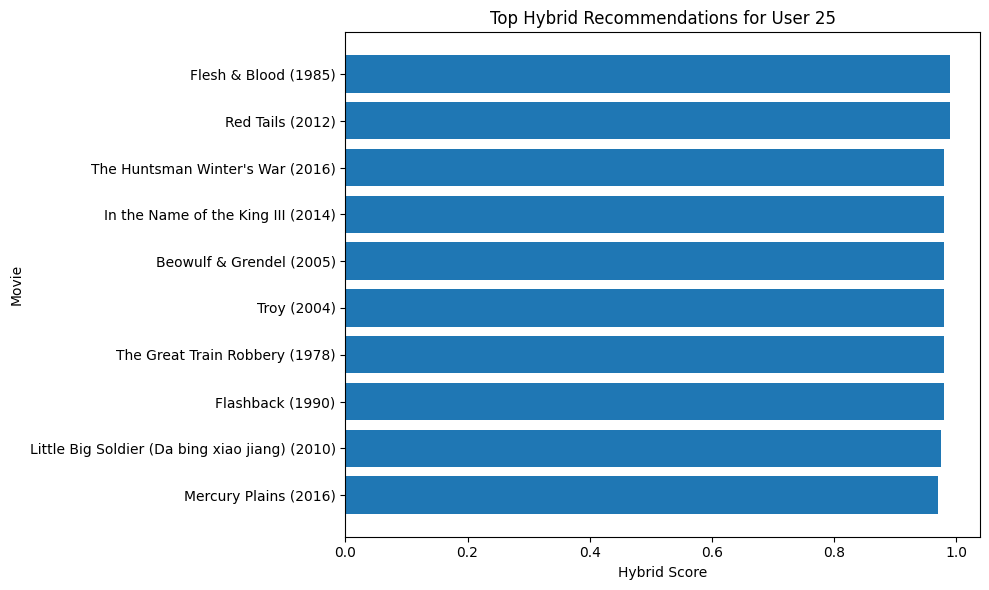

In [ ]:
# 15. DEMONSTRATE HYBRID RECOMMENDATIONS
# ------------------------------------------------------------

demo_recommendations = recommend_hybrid(
    DEMO_USER_ID,
    top_n=TOP_N,
    alpha=ALPHA
)

print('\n' + '=' * 70)
print(f'TOP {TOP_N} HYBRID RECOMMENDATIONS FOR USER {DEMO_USER_ID}')
print('=' * 70)
print(f'Hybrid = {ALPHA:.2f} CF + {1 - ALPHA:.2f} Content')
display(demo_recommendations)

if not demo_recommendations.empty:
    plot_data = demo_recommendations.sort_values('Hybrid Score')

    plt.figure(figsize=(10, 6))
    plt.barh(plot_data['Movie'], plot_data['Hybrid Score'])
    plt.xlabel('Hybrid Score')
    plt.ylabel('Movie')
    plt.title(f'Top Hybrid Recommendations for User {DEMO_USER_ID}')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------


## 16. PREPARE RANKING EVALUATION


In [ ]:
# 16. PREPARE RANKING EVALUATION
# ------------------------------------------------------------

eligible_test = test_data[
    test_data['rating'] >= RELEVANCE_THRESHOLD
].copy()

eligible_test = eligible_test[
    eligible_test['userId'].isin(train_matrix.index)
]

eligible_test = eligible_test[
    eligible_test['movieId'].isin(model_movie_ids)
]

if MAX_EVAL_USERS is not None and len(eligible_test) > MAX_EVAL_USERS:
    eligible_test = (
        eligible_test
        .sample(n=MAX_EVAL_USERS, random_state=EVAL_RANDOM_STATE)
        .sort_values('userId')
    )

print('\nEligible evaluation users:', len(eligible_test))

# ------------------------------------------------------------



Eligible evaluation users: 354


## 17. RANKING HELPERS


In [ ]:
# 17. RANKING HELPERS
# ------------------------------------------------------------

def target_rank(scores, target_pos):
    target_score = scores[target_pos]

    if not np.isfinite(target_score):
        return None

    valid = np.isfinite(scores)

    return int(
        np.sum(scores[valid] > target_score)
    ) + 1


def metrics_from_rank(rank, k=RANKING_K):
    hit = int(rank is not None and rank <= k)
    rr = 1.0 / rank if hit else 0.0
    ndcg = 1.0 / np.log2(rank + 1) if hit else 0.0
    return hit, rr, ndcg

# ------------------------------------------------------------


## 18. EVALUATE CF, CONTENT, AND HYBRID


In [ ]:
# 18. EVALUATE CF, CONTENT, AND HYBRID
# ------------------------------------------------------------

evaluation_rows = []

for number, row in enumerate(eligible_test.itertuples(), start=1):
    target_pos = movie_to_pos[row.movieId]

    cf_scores, content_scores, hybrid_scores = hybrid_scores_for_user(
        row.userId,
        alpha=ALPHA
    )

    cf_rank = target_rank(cf_scores, target_pos)
    content_rank = target_rank(content_scores, target_pos)
    hybrid_rank = target_rank(hybrid_scores, target_pos)

    cf_hit, cf_rr, cf_ndcg = metrics_from_rank(cf_rank)
    cb_hit, cb_rr, cb_ndcg = metrics_from_rank(content_rank)
    h_hit, h_rr, h_ndcg = metrics_from_rank(hybrid_rank)

    evaluation_rows.append({
        'userId': row.userId,
        'movieId': row.movieId,
        'Target Rating': row.rating,
        'CF Rank': cf_rank,
        'CF Hit': cf_hit,
        'CF RR': cf_rr,
        'CF NDCG': cf_ndcg,
        'Content Rank': content_rank,
        'Content Hit': cb_hit,
        'Content RR': cb_rr,
        'Content NDCG': cb_ndcg,
        'Hybrid Rank': hybrid_rank,
        'Hybrid Hit': h_hit,
        'Hybrid RR': h_rr,
        'Hybrid NDCG': h_ndcg
    })

    if number == 1 or number % 100 == 0:
        print(f'Evaluated {number} / {len(eligible_test)} users')

evaluation_results = pd.DataFrame(evaluation_rows)

if evaluation_results.empty:
    raise ValueError('No users were available for ranking evaluation.')

# ------------------------------------------------------------


Evaluated 1 / 354 users
Evaluated 100 / 354 users
Evaluated 200 / 354 users
Evaluated 300 / 354 users


## 19. MODEL COMPARISON TABLE


In [ ]:
# 19. MODEL COMPARISON TABLE
# ------------------------------------------------------------

comparison = pd.DataFrame({
    'Model': [
        'Collaborative Filtering',
        'Content-Based',
        'Hybrid'
    ],
    f'HR@{RANKING_K}': [
        evaluation_results['CF Hit'].mean(),
        evaluation_results['Content Hit'].mean(),
        evaluation_results['Hybrid Hit'].mean()
    ],
    f'MRR@{RANKING_K}': [
        evaluation_results['CF RR'].mean(),
        evaluation_results['Content RR'].mean(),
        evaluation_results['Hybrid RR'].mean()
    ],
    f'NDCG@{RANKING_K}': [
        evaluation_results['CF NDCG'].mean(),
        evaluation_results['Content NDCG'].mean(),
        evaluation_results['Hybrid NDCG'].mean()
    ]
})

print('\n' + '=' * 70)
print('MODEL COMPARISON')
print('=' * 70)
display(comparison)

# ------------------------------------------------------------



## 20. HYBRID IMPROVEMENT TABLE


In [ ]:
# 20. HYBRID IMPROVEMENT TABLE
# ------------------------------------------------------------

hybrid_row = comparison[comparison['Model'] == 'Hybrid'].iloc[0]
cf_row = comparison[comparison['Model'] == 'Collaborative Filtering'].iloc[0]
content_row = comparison[comparison['Model'] == 'Content-Based'].iloc[0]

improvement_rows = []

for metric in [
    f'HR@{RANKING_K}',
    f'MRR@{RANKING_K}',
    f'NDCG@{RANKING_K}'
]:
    hybrid_value = float(hybrid_row[metric])

    for baseline_name, baseline_row in [
        ('Collaborative Filtering', cf_row),
        ('Content-Based', content_row)
    ]:
        baseline_value = float(baseline_row[metric])

        improvement = (
            (hybrid_value - baseline_value) / baseline_value * 100.0
            if baseline_value > 0
            else np.nan
        )

        improvement_rows.append({
            'Metric': metric,
            'Compared With': baseline_name,
            'Baseline Value': baseline_value,
            'Hybrid Value': hybrid_value,
            'Improvement (%)': improvement
        })

improvement_table = pd.DataFrame(improvement_rows)

print('\n' + '=' * 70)
print('HYBRID IMPROVEMENT')
print('=' * 70)
display(improvement_table)

# ------------------------------------------------------------


## 21. VISUALIZE MODEL COMPARISON


In [ ]:
# 21. VISUALIZE MODEL COMPARISON
# ------------------------------------------------------------

metrics_to_plot = [
    f'HR@{RANKING_K}',
    f'MRR@{RANKING_K}',
    f'NDCG@{RANKING_K}'
]

x = np.arange(len(comparison['Model']))
width = 0.24

plt.figure(figsize=(10, 6))

for index, metric in enumerate(metrics_to_plot):
    plt.bar(
        x + (index - 1) * width,
        comparison[metric],
        width,
        label=metric
    )

plt.xticks(x, comparison['Model'])
plt.ylabel('Metric Value')
plt.title('Collaborative vs Content-Based vs Hybrid')
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
